# 4.2 · A factor dashboard for any registered strategies

S&P Dow Jones Indices publishes a monthly **Dashboard: S&P 500 Factor Indices**: each factor index's return over the
month and over longer horizons, its risk, its tracking error against the S&P 500, its holdings and its factor
exposures. This notebook builds the same views for **any registered strategies of one universe**: list their run ids
in `RUNS` (each strategy notebook prints the ids of the runs it registers), with a label each.

Each run is rebuilt from its registered configuration and backtested again - **not registered again**, so the
registry's trial counts and deflated Sharpe ratios do not move. The rerun uses today's data and code; the table below
the parameters sets its main numbers beside the registered ones, so a difference is seen, not assumed away. Every
book is compared with an **Equal Weight** book of the same universe, with the universe weighted by market value (the
*index*), and with a benchmark fund measured with its dividends (`BENCHMARK`).

**The default books** rebuild S&P's dashboard: S&P's official indices are not licensed to us, so each "index" is
**our own backtested portfolio** on the S&P 500's constituents of each date, built in the spirit of S&P's rules:

| Portfolio | Run | Construction (rebalanced quarterly, net of costs) |
|---|---|---|
| Value | 84 | the top 20 % by value score, cap-weighted |
| Quality | 85 | the top 20 % by quality score, cap-weighted |
| Momentum | 86 | the top 20 % by 12-1 month momentum, cap-weighted |
| Low Volatility | 87 | the 20 % with the lowest return volatility, equally weighted (S&P weights by inverse volatility) |
| High Beta | 88 | the 20 % with the highest market beta, equally weighted (S&P weights by beta) |
| High Dividend | 89 | the 16 % (about 80) with the highest dividend yield, equally weighted |
| Buyback | 90 | the 20 % with the largest reduction in shares outstanding over the year, equally weighted |
| GARP | 36 | the reconstruction of the S&P 500 GARP Index (notebook 3.5) |
| Equal Weight | - | every constituent at the same weight, rebalanced quarterly |

S&P's Growth, Pure Growth/Value, Revenue-Weighted, Economic Moat and Aristocrats indices are omitted: they need style
scores, Morningstar's moat ratings or 25 years of dividend history that we do not have. The dashboard date is the last
day every backtest reaches - **31 December 2024** for the default books, the last month end before our hold-out; the
benchmark is **SPY** (the S&P 500 with dividends). Statistics over many years use the longest period every book
covers (15 years for the default books).

In [1]:
# The books to compare: a label and a registered run id each, all of one universe. The default rebuilds S&P's
# factor dashboard: seven factor books (runs 84-90) and the S&P 500 GARP reconstruction (run 36).
RUNS = {
    "Value": 84,
    "Quality": 85,
    "Momentum": 86,
    "Low Volatility": 87,
    "High Beta": 88,
    "High Dividend": 89,
    "Buyback": 90,
    "GARP": 36,
}
BENCHMARK = "SPY"  # a fund's Yahoo symbol, measured with its dividends (SPTM for the S&P 1500)
ASOF = None  # the dashboard date (None: the last day every backtest reaches)
FOCUS = "Momentum"  # the book whose sector weights around its last rebalance are shown (default: the first)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import dashboard as db
from equity_research.research.cache import ResearchCache
from equity_research.research.classification import listing_sectors
from equity_research.research.data import load_universe_data
from equity_research.research.indices import calendar_years, equal_weighted, vendor_returns
from equity_research.research.runs import load_run, one_universe, rerun

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()
cache = ResearchCache()
engine = get_engine()

registered = {name: load_run(engine, run_id) for name, run_id in RUNS.items()}
universe = one_universe(r.config for r in registered.values())
results = {name: rerun(cache, r.config) for name, r in registered.items()}  # not registered again: no trial added
asof = pd.Timestamp(ASOF) if ASOF else min(r.backtest.net.index.max() for r in results.values())
display(
    pd.DataFrame(
        {
            name: {
                "run": registered[name].label,
                "CAGR registered": registered[name].metrics.get("cagr"),
                "CAGR now": results[name].metrics.get("cagr"),
                "Sharpe registered": registered[name].metrics.get("sharpe"),
                "Sharpe now": results[name].metrics.get("sharpe"),
            }
            for name in RUNS
        }
    ).T.style.format(
        {c: "{:.2%}" for c in ("CAGR registered", "CAGR now")}
        | {c: "{:.2f}" for c in ("Sharpe registered", "Sharpe now")}
    )
)

start = min(r.config.start for r in registered.values())
data = load_universe_data(cache, universe, start, asof.strftime("%Y-%m-%d"))
INDEX = cache.query("SELECT name FROM ref.universe WHERE code = ?", [universe])["name"].iloc[0]
bench = vendor_returns(cache, BENCHMARK, total=True)
daily = {name: r.backtest.net for name, r in results.items()}
daily["Equal Weight"] = equal_weighted(data.returns, data.members)["return"]
day = data.rebalances[data.rebalances <= asof].max()  # the last decision date: holdings, ratios, market values
members = data.members.loc[day]
held = {name: r.book.loc[:asof].iloc[-1] for name, r in results.items()}
held["Equal Weight"] = members[members].astype(float) / members.sum()
held = {name: w[w > 0] for name, w in held.items()}
caps = data.market_cap.loc[day].where(members).dropna()
index_weights = caps / caps.sum()  # the universe by market value: what an index fund holds
sectors = listing_sectors(cache, data.members.columns, day)
SHORT = {
    "Information Technology": "IT",
    "Communication Services": "Communications",
    "Consumer Discretionary": "Cons. Disc.",
    "Consumer Staples": "Cons. Staples",
    "Health Care": "Health Care",
    "Real Estate": "Real Estate",
}
sectors = sectors.replace(SHORT)
all_returns = db.period_returns(daily | {BENCHMARK: bench}, asof)
HORIZON = db.longest_period(all_returns)  # the longest period every book covers
SPAN = HORIZON.replace("Y", "-year").replace("M", "-month")
since = db.period_start(HORIZON, asof)
print(f"{len(RUNS)} books of {INDEX} on {asof:%d %B %Y}, against {BENCHMARK}; long-run statistics: {HORIZON}")

left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


left out 730 facts of 1 companies in ['GBP']


,run,CAGR registered,CAGR now,Sharpe registered,Sharpe now
Value,run 84 · sp500_factor_dashboard: value,10.74%,10.74%,0.60,0.60
Quality,run 85 · sp500_factor_dashboard: quality,15.62%,15.62%,0.90,0.90
Momentum,run 86 · sp500_factor_dashboard: momentum,13.44%,13.44%,0.72,0.72
Low Volatility,run 87 · sp500_factor_dashboard: low_vol,11.85%,11.85%,0.86,0.86
High Beta,run 88 · sp500_factor_dashboard: high_beta,11.92%,11.92%,0.55,0.55
High Dividend,run 89 · sp500_factor_dashboard: dividend_yield,13.22%,13.22%,0.77,0.77
Buyback,run 90 · sp500_factor_dashboard: issuance,13.59%,13.59%,0.77,0.77
GARP,run 36 · garp_sp500,12.41%,12.51%,0.71,0.71


left out 730 facts of 1 companies in ['GBP']


8 books of S&P 500 on 31 December 2024, against SPY; long-run statistics: 15Y


## Monthly and year-to-date performance

Each book's return for the month and the year to date, with the benchmark's as the dashed line; then each book's
excess return over the benchmark for the month plotted against its excess return for the year to date.

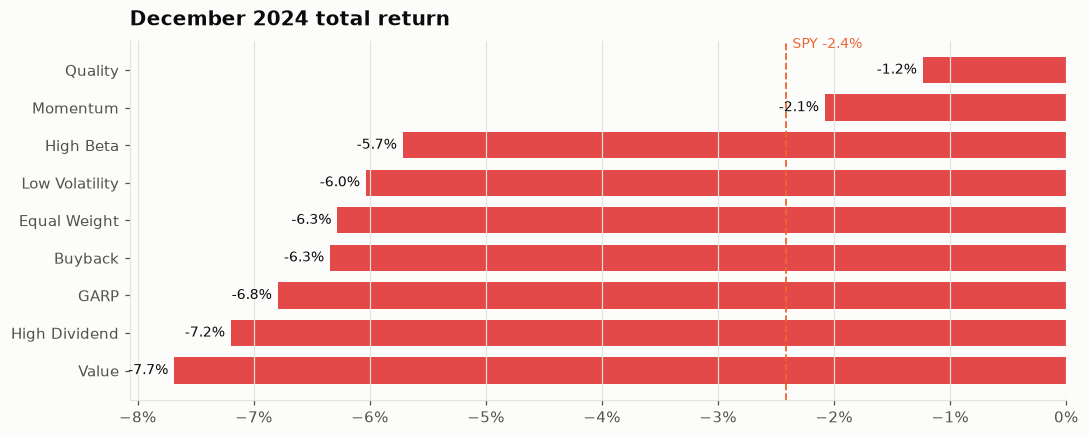

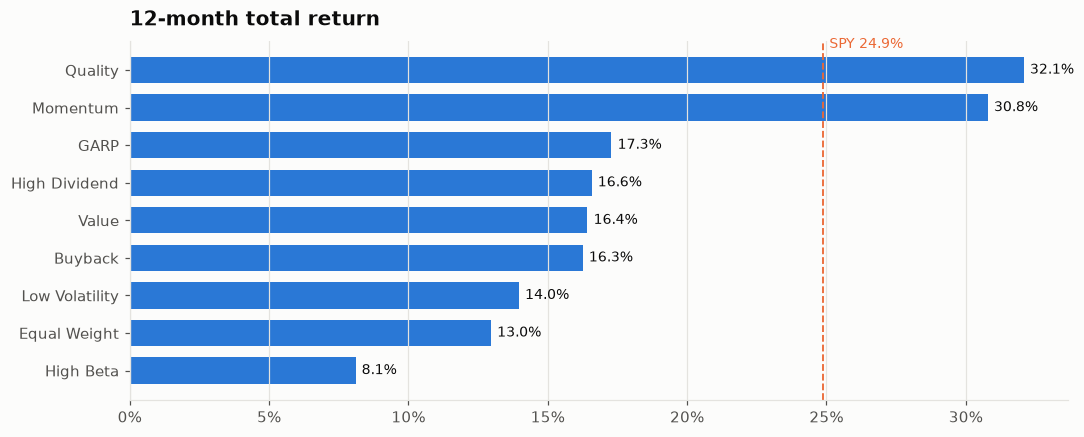

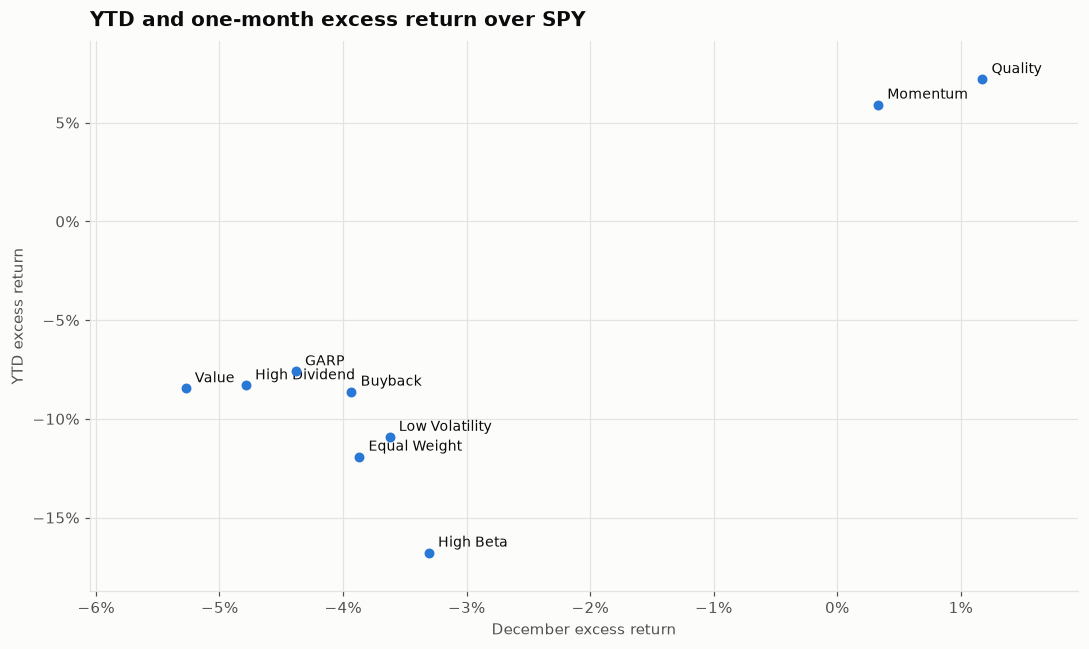

In [3]:
returns = db.period_returns(daily, asof)
bench_returns = pd.Series({p: db.period_return(bench, p, asof) for p in db.PERIODS})
fig = charts.ranked_bars(
    returns["1M"], f"{asof:%B %Y} total return", percent=True, reference=(BENCHMARK, bench_returns["1M"])
)
fig = charts.ranked_bars(
    returns["12M"], "12-month total return", percent=True, reference=(BENCHMARK, bench_returns["12M"])
)
excess, tracking = db.relative_to(daily, bench, asof)
points = pd.DataFrame({"x": excess["1M"], "y": excess["YTD"]})
fig = charts.labeled_scatter(
    points,
    f"YTD and one-month excess return over {BENCHMARK}",
    xlabel=f"{asof:%B} excess return",
    ylabel="YTD excess return",
)

### Rolling three-month excess return

Each book's trailing three-month return minus the benchmark's, computed daily over the past year.

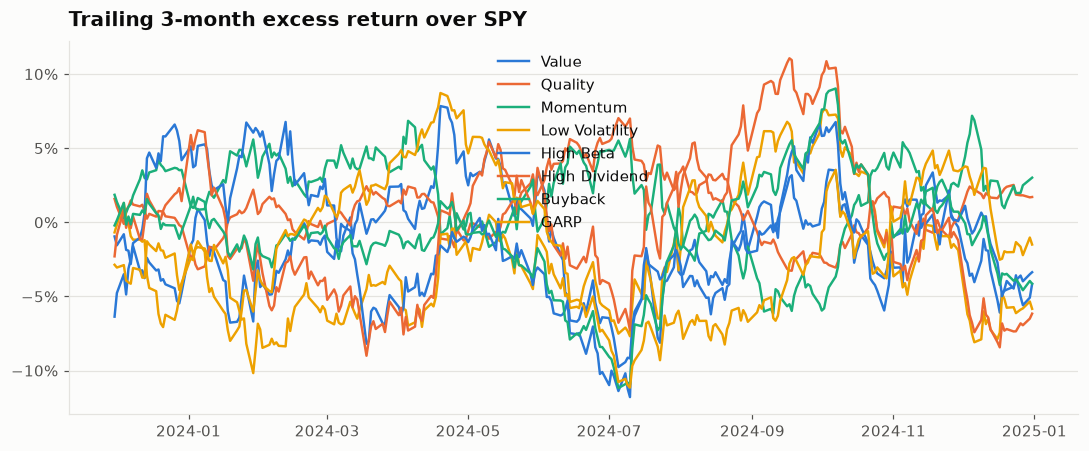

In [4]:
year_ago = asof - pd.DateOffset(months=13)
trailing = {name: db.trailing_excess(daily[name], bench).loc[year_ago:asof] for name in RUNS}
fig = charts.lines(trailing, f"Trailing 3-month excess return over {BENCHMARK}", percent=True)

### One book's sector weights around its last rebalance

How the `FOCUS` book's sector weights changed at its last rebalance inside the period. A momentum book's sector
weights swing more than other factors' because it buys whatever has recently risen, often whole sectors at once.
(S&P shows industry groups; our sectors are today's GICS sectors.)

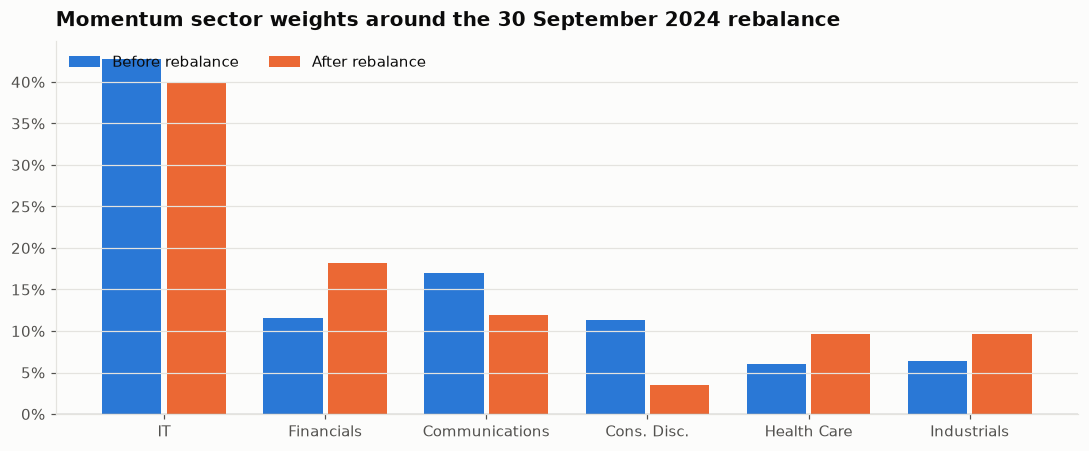

In [5]:
focus = FOCUS if FOCUS in results else next(iter(results))
book = results[focus].book
last = book.index[book.index < asof].max()
weights_held = results[focus].backtest.weights
before = weights_held.loc[:last].iloc[-1]
after = weights_held.loc[weights_held.index > last].iloc[0]
change = pd.DataFrame(
    {"Before rebalance": db.sector_weights(before, sectors), "After rebalance": db.sector_weights(after, sectors)}
).fillna(0.0)
change = change.loc[change.max(axis=1).sort_values(ascending=False).index[:6]]
fig = charts.yearly_bars(change, f"{focus} sector weights around the {last:%d %B %Y} rebalance")

## Calendar-year performance

Each book year by year over the long-run period, and each one's excess return over the benchmark.

trade_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Value,22.1%,-4.9%,21.2%,36.1%,8.7%,-8.2%,20.0%,21.7%,-12.4%,30.1%,-5.3%,29.8%,-6.2%,7.9%,16.4%
Quality,8.4%,7.6%,13.6%,28.0%,18.3%,3.9%,7.5%,29.0%,-3.4%,38.8%,27.2%,31.0%,-25.5%,38.2%,32.1%
Momentum,15.6%,-6.0%,17.4%,32.6%,11.8%,7.6%,4.4%,24.5%,-0.5%,29.4%,27.9%,24.8%,-16.0%,10.8%,30.8%
Low Volatility,13.1%,12.7%,11.9%,24.3%,18.6%,5.0%,10.2%,18.2%,-0.0%,28.1%,5.7%,24.8%,-3.6%,0.4%,14.0%
High Beta,34.7%,-14.1%,19.0%,39.8%,12.1%,-14.1%,22.6%,16.9%,-17.0%,28.3%,15.9%,36.3%,-13.7%,29.5%,8.1%
High Dividend,19.8%,12.2%,10.5%,30.4%,20.9%,-4.8%,22.0%,12.3%,-4.1%,24.8%,0.5%,36.2%,2.8%,6.9%,16.6%
Buyback,16.3%,5.0%,17.6%,48.2%,14.2%,-3.7%,16.5%,17.9%,-9.0%,30.3%,6.0%,33.3%,-9.2%,18.6%,16.3%
GARP,12.7%,3.4%,12.7%,37.6%,11.8%,-7.0%,9.5%,23.7%,-13.3%,28.6%,12.4%,32.6%,-17.3%,21.9%,17.3%
SPY,15.1%,1.9%,16.0%,32.3%,13.5%,1.3%,12.0%,21.7%,-4.6%,31.2%,18.4%,28.7%,-18.2%,26.2%,24.9%


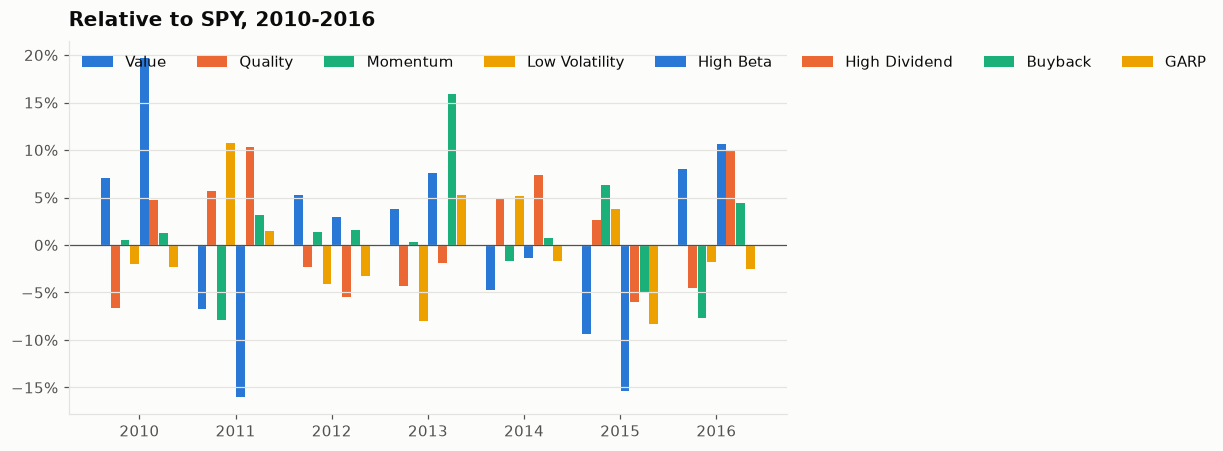

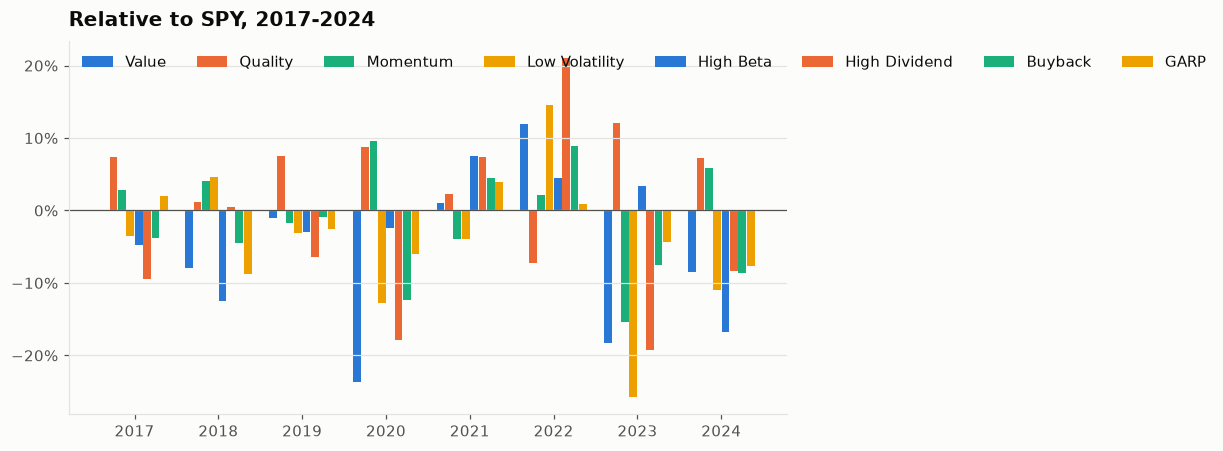

In [6]:
books = list(RUNS)
years = calendar_years({name: daily[name] for name in books} | {BENCHMARK: bench})
years = years.loc[(years.index > since.year) & (years.index <= asof.year)]
display(years.T.style.format("{:.1%}"))
relative = years[books].sub(years[BENCHMARK], axis=0)
halves = [relative.iloc[: len(relative) // 2], relative.iloc[len(relative) // 2 :]]
for part in halves:
    fig = charts.yearly_bars(part, f"Relative to {BENCHMARK}, {part.index.min()}-{part.index.max()}")

## Long-run risk and return

Each book's annualised return against its annualised volatility over the longest period every book covers (15 years,
2010-2024, for the default books), then both statistics over every horizon.

Total return (a year beyond 12 months)


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Quality,-1.2%,3.8%,32.1%,32.1%,10.8%,17.8%,15.9%,15.6%
SPY,-2.4%,2.5%,24.9%,24.9%,8.8%,14.5%,13.0%,13.8%
Buyback,-6.3%,-0.9%,16.3%,16.3%,7.8%,12.1%,10.7%,13.6%
Momentum,-2.1%,4.8%,30.8%,30.8%,6.8%,14.2%,13.3%,13.4%
High Dividend,-7.2%,-3.1%,16.6%,16.6%,8.6%,11.9%,10.6%,13.2%
Equal Weight,-6.3%,-1.9%,13.0%,13.0%,4.8%,10.9%,10.4%,12.7%
High Beta,-5.7%,-2.3%,8.1%,8.1%,6.5%,13.8%,9.6%,11.9%
Low Volatility,-6.0%,-2.3%,14.0%,14.0%,3.3%,7.8%,9.8%,11.8%
GARP,-6.8%,2.1%,17.3%,17.3%,5.8%,12.0%,9.5%,11.3%
Value,-7.7%,-0.1%,16.4%,16.4%,5.6%,7.7%,8.3%,10.7%


Volatility (a year)


,12M,3Y,5Y,10Y,15Y
Value,15.7%,20.1%,23.1%,19.6%,18.3%
Quality,12.2%,18.9%,19.3%,16.1%,15.0%
Momentum,14.9%,18.8%,19.4%,16.2%,16.1%
Low Volatility,11.6%,13.4%,15.8%,12.9%,11.8%
High Beta,16.7%,26.9%,31.5%,26.2%,25.0%
High Dividend,15.0%,19.0%,23.5%,18.2%,16.2%
Buyback,15.7%,19.0%,22.4%,18.9%,17.2%
GARP,16.2%,20.2%,21.6%,18.4%,17.2%
Equal Weight,13.6%,18.6%,20.5%,17.0%,16.2%
SPY,10.7%,17.4%,18.2%,15.3%,14.6%


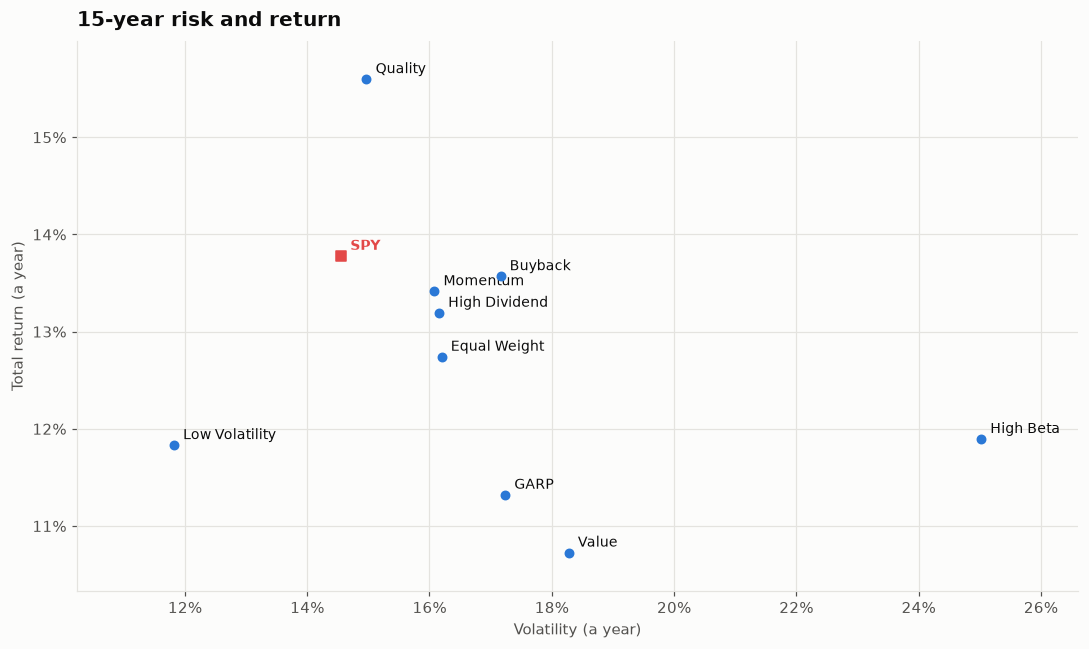

In [7]:
vols = db.period_volatility(daily | {BENCHMARK: bench}, asof)
points = pd.DataFrame({"x": vols[HORIZON], "y": all_returns[HORIZON]})
fig = charts.labeled_scatter(
    points,
    f"{SPAN} risk and return",
    xlabel="Volatility (a year)",
    ylabel="Total return (a year)",
    highlight=BENCHMARK,
)


def red_negatives(v: float) -> str:
    """Negative numbers in red, as in the dashboard."""
    return "color: #e34948" if isinstance(v, float) and v < 0 else ""


print("Total return (a year beyond 12 months)")
display(all_returns.sort_values(HORIZON, ascending=False).style.format("{:.1%}", na_rep="-").map(red_negatives))
print("Volatility (a year)")
display(vols.style.format("{:.1%}", na_rep="-"))

## Relative to the benchmark

Long-run annualised excess return against tracking error - how much active risk each book took for what it added -
then both over every horizon. Their ratio is the information ratio.

Performance less SPY


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Quality,+1.2%,+1.3%,+7.2%,+7.2%,+2.0%,+3.3%,+2.9%,+1.8%
Buyback,-3.9%,-3.4%,-8.6%,-8.6%,-1.1%,-2.4%,-2.3%,-0.2%
Momentum,+0.3%,+2.3%,+5.9%,+5.9%,-2.1%,-0.3%,+0.3%,-0.4%
High Dividend,-4.8%,-5.6%,-8.3%,-8.3%,-0.2%,-2.6%,-2.4%,-0.6%
Equal Weight,-3.9%,-4.4%,-11.9%,-11.9%,-4.1%,-3.5%,-2.6%,-1.0%
High Beta,-3.3%,-4.7%,-16.8%,-16.8%,-2.3%,-0.7%,-3.4%,-1.9%
Low Volatility,-3.6%,-4.8%,-10.9%,-10.9%,-5.5%,-6.7%,-3.2%,-1.9%
GARP,-4.4%,-0.4%,-7.6%,-7.6%,-3.1%,-2.5%,-3.5%,-2.5%
Value,-5.3%,-2.6%,-8.5%,-8.5%,-3.2%,-6.8%,-4.7%,-3.1%


Tracking error to SPY (a year)


,12M,3Y,5Y,10Y,15Y
Value,10.7%,11.7%,12.3%,10.0%,8.7%
Quality,4.9%,5.0%,5.4%,4.8%,4.6%
Momentum,7.7%,8.6%,8.6%,7.2%,6.8%
Low Volatility,7.7%,9.5%,8.9%,8.1%,7.9%
High Beta,11.5%,14.9%,18.9%,15.4%,14.2%
High Dividend,11.5%,12.3%,13.5%,10.6%,9.4%
Buyback,9.2%,8.6%,9.6%,7.8%,6.6%
GARP,9.7%,8.1%,7.5%,6.5%,6.0%
Equal Weight,7.2%,6.6%,6.7%,5.2%,4.5%


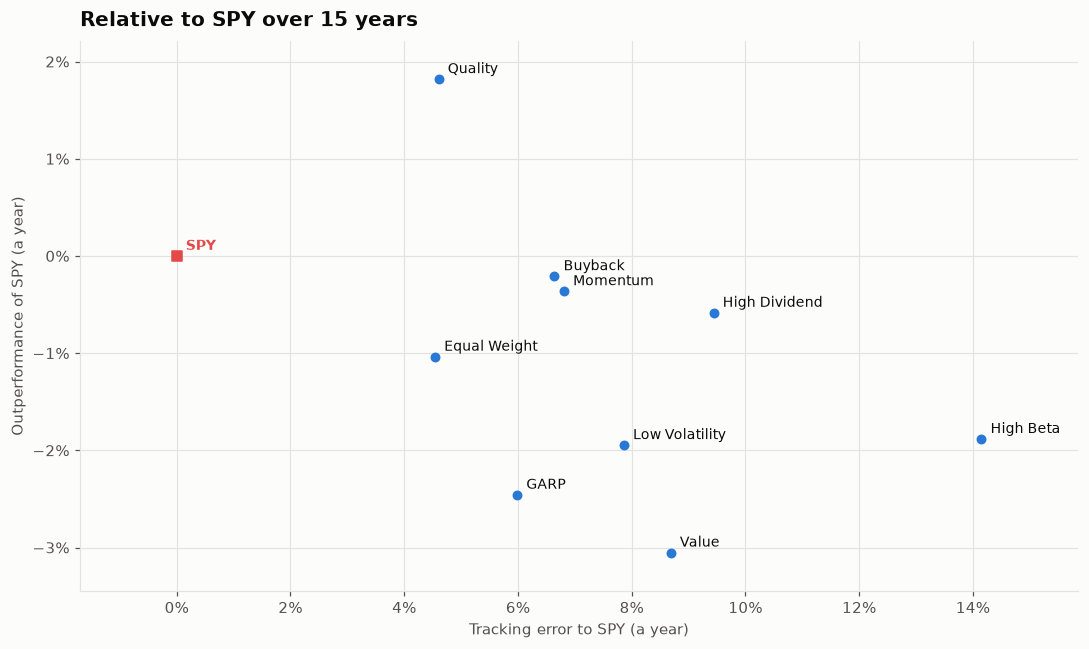

In [8]:
points = pd.DataFrame({"x": tracking[HORIZON], "y": excess[HORIZON]})
points.loc[BENCHMARK] = [0.0, 0.0]
fig = charts.labeled_scatter(
    points,
    f"Relative to {BENCHMARK} over {SPAN.replace('-', ' ')}s",
    xlabel=f"Tracking error to {BENCHMARK} (a year)",
    ylabel=f"Outperformance of {BENCHMARK} (a year)",
    highlight=BENCHMARK,
)
print(f"Performance less {BENCHMARK}")
display(excess.sort_values(HORIZON, ascending=False).style.format("{:+.1%}", na_rep="-").map(red_negatives))
print(f"Tracking error to {BENCHMARK} (a year)")
display(tracking.style.format("{:.1%}", na_rep="-"))

## Holdings overlap and excess-return correlations

**Overlap** is the weight two books hold in common on the dashboard date, $\sum_i \min(w_i^A, w_i^B)$.
**Excess-return correlation** is the correlation of the books' monthly returns *over the benchmark* across the
long-run period: two books with highly correlated excess returns are largely the same active bet, whatever their
labels.

In [9]:
names = list(held)
overlap = db.portfolio_overlap({name: held[name] for name in names} | {INDEX: index_weights})
display(overlap.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1))
correlations = db.excess_correlations(daily, bench, HORIZON, asof)
display(correlations.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,Value,Quality,Momentum,Low Volatility,High Beta,High Dividend,Buyback,GARP,Equal Weight,S&P 500
Value,100%,3%,14%,8%,13%,16%,23%,19%,21%,13%
Quality,3%,100%,31%,13%,3%,2%,7%,13%,17%,52%
Momentum,14%,31%,100%,10%,14%,7%,13%,9%,19%,31%
Low Volatility,8%,13%,10%,100%,0%,24%,17%,7%,22%,21%
High Beta,13%,3%,14%,0%,100%,17%,19%,16%,22%,12%
High Dividend,16%,2%,7%,24%,17%,100%,5%,9%,17%,9%
Buyback,23%,7%,13%,17%,19%,5%,100%,26%,22%,13%
GARP,19%,13%,9%,7%,16%,9%,26%,100%,15%,14%
Equal Weight,21%,17%,19%,22%,22%,17%,22%,15%,100%,46%
S&P 500,13%,52%,31%,21%,12%,9%,13%,14%,46%,100%


,Value,Quality,Momentum,Low Volatility,High Beta,High Dividend,Buyback,GARP,Equal Weight
Value,1.00,-0.60,-0.32,-0.11,0.65,0.55,0.78,0.57,0.73
Quality,-0.60,1.00,0.18,-0.04,-0.54,-0.48,-0.50,-0.25,-0.66
Momentum,-0.32,0.18,1.00,-0.03,-0.28,-0.28,-0.33,-0.26,-0.26
Low Volatility,-0.11,-0.04,-0.03,1.00,-0.53,0.45,0.01,-0.18,0.05
High Beta,0.65,-0.54,-0.28,-0.53,1.00,0.33,0.63,0.51,0.75
High Dividend,0.55,-0.48,-0.28,0.45,0.33,1.00,0.63,0.27,0.65
Buyback,0.78,-0.50,-0.33,0.01,0.63,0.63,1.00,0.70,0.84
GARP,0.57,-0.25,-0.26,-0.18,0.51,0.27,0.70,1.00,0.64
Equal Weight,0.73,-0.66,-0.26,0.05,0.75,0.65,0.84,0.64,1.00


## Tracking error, active share and factor exposures

**Active share** (Cremers and Petajisto, 2009) is half the sum of absolute weight differences from the index (the
universe by market value), $\frac{1}{2}\sum_i |w_i - w_i^{b}|$: the fraction of the book that differs from the index
(0 % = identical, 100 % = no holdings in common). **Exposure** is the book's weighted-average factor z-score minus the
index's, in cross-sectional standard deviations (S&P scales its exposures differently, from -100 % to +100 %).

,Low Volatility,Momentum,Value,High Beta,Dividend,Quality,Small Size
Value,+0.43,-0.06,+1.27,-0.86,+0.79,-0.49,+0.55
Quality,-0.01,+0.20,-0.22,+0.26,-0.36,+0.29,-0.54
Momentum,-0.69,+1.06,-0.10,+0.59,-0.12,-0.08,-0.22
Low Volatility,+1.16,+0.00,+0.27,-1.31,+0.70,-0.30,+1.23
High Beta,-0.88,-0.45,+0.45,+0.69,+0.11,-0.24,+1.78
High Dividend,+0.47,-0.42,+0.62,-1.06,+2.01,-0.34,+1.79
Buyback,+0.13,-0.32,+0.72,-0.58,+0.09,-0.39,+1.70
GARP,-0.32,-0.43,+0.76,-0.19,+0.14,+0.03,+1.58
Equal Weight,+0.12,-0.37,+0.36,-0.50,+0.37,-0.23,+1.59


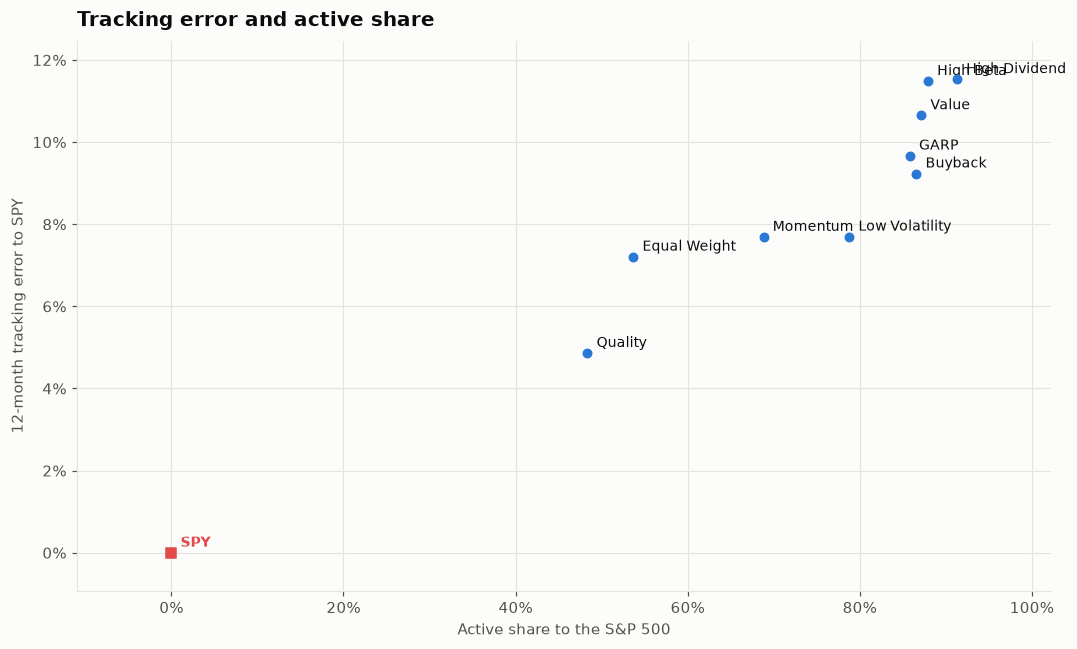

In [10]:
traits = db.stock_characteristics(data, day, bench)
scores = db.factor_z(traits, members)
active = pd.Series({name: db.active_share(w, index_weights) for name, w in held.items()})
points = pd.DataFrame({"x": active, "y": tracking["12M"]})
points.loc[BENCHMARK] = [0.0, 0.0]
fig = charts.labeled_scatter(
    points,
    "Tracking error and active share",
    xlabel=f"Active share to the {INDEX}",
    ylabel=f"12-month tracking error to {BENCHMARK}",
    highlight=BENCHMARK,
)
exposure = pd.DataFrame({name: db.exposures(w, index_weights, scores) for name, w in held.items()}).T
display(exposure.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5))

## Portfolio detail

For each book: returns and risk over each horizon, how its holdings differ from the index, the weighted-average
characteristics of its holdings, its sector tilts, and its factor exposures (the dashed ring is the index).


==================== Value ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-7.7%,-0.1%,16.4%,16.4%,5.6%,7.7%,8.3%,10.7%
Relative to SPY,-5.3%,-2.6%,-8.5%,-8.5%,-3.2%,-6.8%,-4.7%,-3.1%
Volatility,-,-,-,15.7%,20.1%,23.1%,19.6%,18.3%
Tracking error,-,-,-,10.7%,11.7%,12.3%,10.0%,8.7%


Book S&P 500
Portfolio         Companies                  114     503
                  Active share (stock)       87%      0%
                  Active share (sector)      51%      0%
                  Concentration (HH index)   346     199
                  Turnover (a year)         1.13       -
                  1-year beta to SPY        0.58    1.00
Weighted averages Stock volatility           24%     28%
                  12M - 1M price return      26%     38%
                  Book / price              0.66    0.20
                  Earnings / price          0.09    0.03
                  Sales / price             1.02    0.32
                  Stock beta                0.59    1.06
                  Yield (12M trailing)      2.6%    1.3%
                  Return on equity            4%     39%
                  Market value (USD bn)      233   1,046

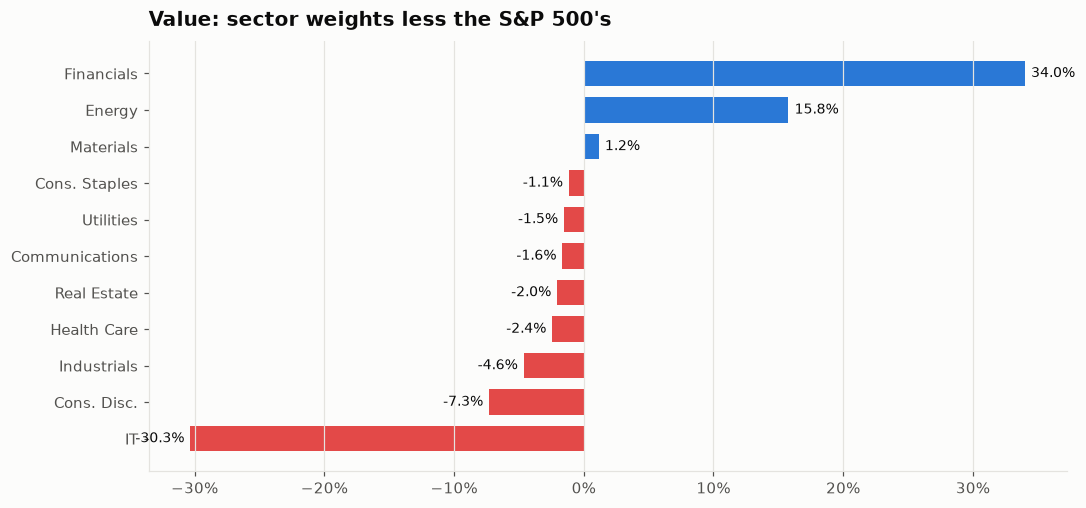

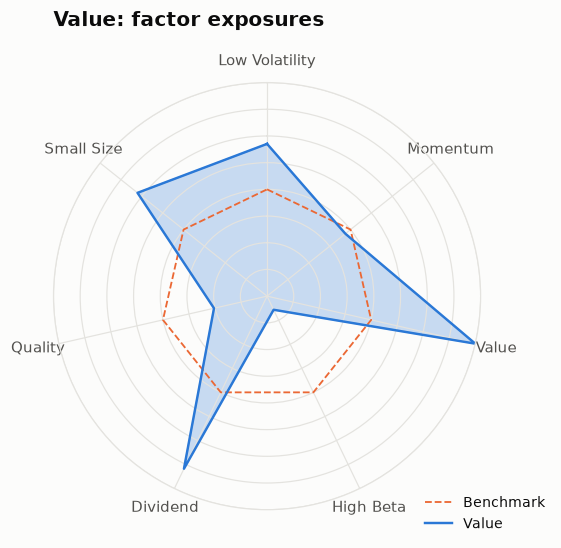


==================== Quality ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-1.2%,3.8%,32.1%,32.1%,10.8%,17.8%,15.9%,15.6%
Relative to SPY,1.2%,1.3%,7.2%,7.2%,2.0%,3.3%,2.9%,1.8%
Volatility,-,-,-,12.2%,18.9%,19.3%,16.1%,15.0%
Tracking error,-,-,-,4.9%,5.0%,5.4%,4.8%,4.6%


Book S&P 500
Portfolio         Companies                   113     503
                  Active share (stock)        48%      0%
                  Active share (sector)       25%      0%
                  Concentration (HH index)    655     199
                  Turnover (a year)          0.87       -
                  1-year beta to SPY         1.16    1.00
Weighted averages Stock volatility            28%     28%
                  12M - 1M price return       47%     38%
                  Book / price               0.09    0.20
                  Earnings / price           0.03    0.03
                  Sales / price              0.20    0.32
                  Stock beta                 1.21    1.06
                  Yield (12M trailing)       0.7%    1.3%
                  Return on equity            60%     39%
                  Market value (USD bn)     1,777   1,046

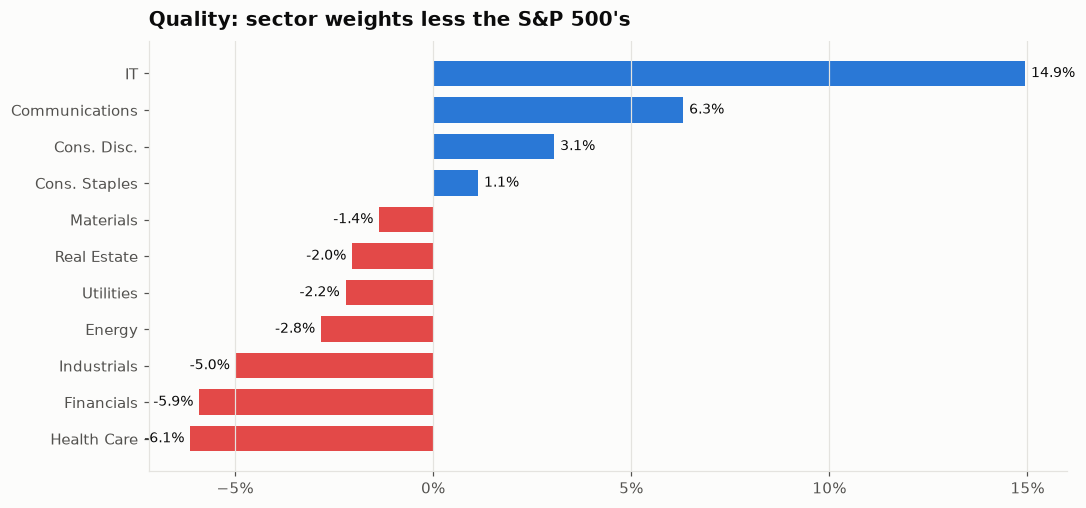

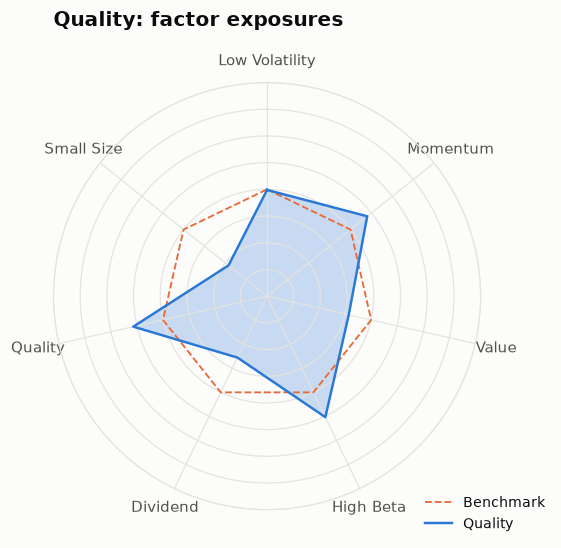


==================== Momentum ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-2.1%,4.8%,30.8%,30.8%,6.8%,14.2%,13.3%,13.4%
Relative to SPY,0.3%,2.3%,5.9%,5.9%,-2.1%,-0.3%,0.3%,-0.4%
Volatility,-,-,-,14.9%,18.8%,19.4%,16.2%,16.1%
Tracking error,-,-,-,7.7%,8.6%,8.6%,7.2%,6.8%


Book S&P 500
Portfolio         Companies                   108     503
                  Active share (stock)        69%      0%
                  Active share (sector)       17%      0%
                  Concentration (HH index)    639     199
                  Turnover (a year)          3.10       -
                  1-year beta to SPY         1.47    1.00
Weighted averages Stock volatility            35%     28%
                  12M - 1M price return       86%     38%
                  Book / price               0.17    0.20
                  Earnings / price           0.03    0.03
                  Sales / price              0.23    0.32
                  Stock beta                 1.44    1.06
                  Yield (12M trailing)       1.1%    1.3%
                  Return on equity            35%     39%
                  Market value (USD bn)     1,047   1,046

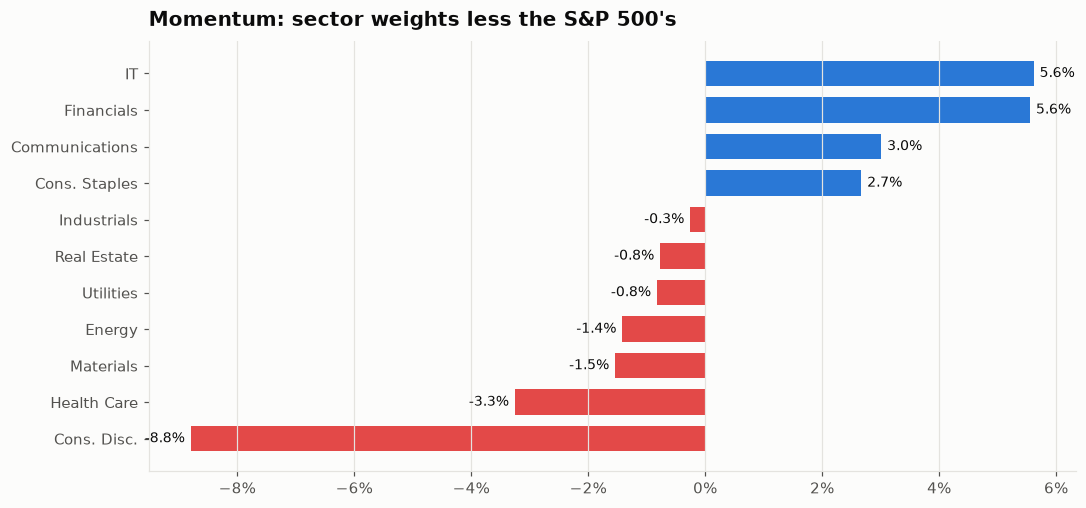

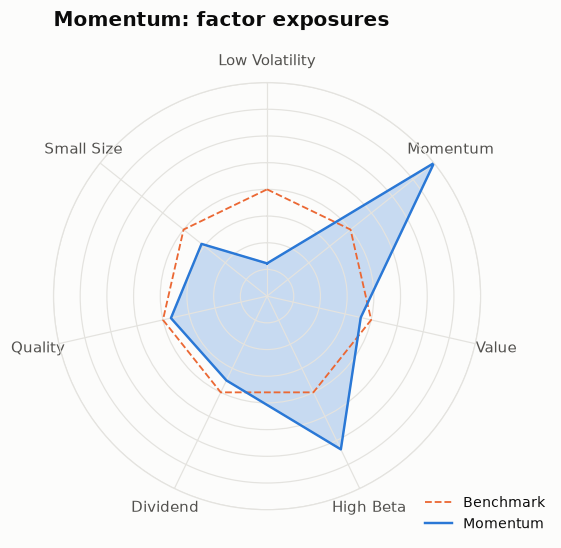


==================== Low Volatility ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-6.0%,-2.3%,14.0%,14.0%,3.3%,7.8%,9.8%,11.8%
Relative to SPY,-3.6%,-4.8%,-10.9%,-10.9%,-5.5%,-6.7%,-3.2%,-1.9%
Volatility,-,-,-,11.6%,13.4%,15.8%,12.9%,11.8%
Tracking error,-,-,-,7.7%,9.5%,8.9%,8.1%,7.9%


Book S&P 500
Portfolio         Companies                  110     503
                  Active share (stock)       79%      0%
                  Active share (sector)      44%      0%
                  Concentration (HH index)    91     199
                  Turnover (a year)         1.09       -
                  1-year beta to SPY        0.39    1.00
Weighted averages Stock volatility           18%     28%
                  12M - 1M price return      22%     38%
                  Book / price              0.32    0.20
                  Earnings / price          0.04    0.03
                  Sales / price             0.43    0.32
                  Stock beta                0.36    1.06
                  Yield (12M trailing)      2.4%    1.3%
                  Return on equity           24%     39%
                  Market value (USD bn)      130   1,046

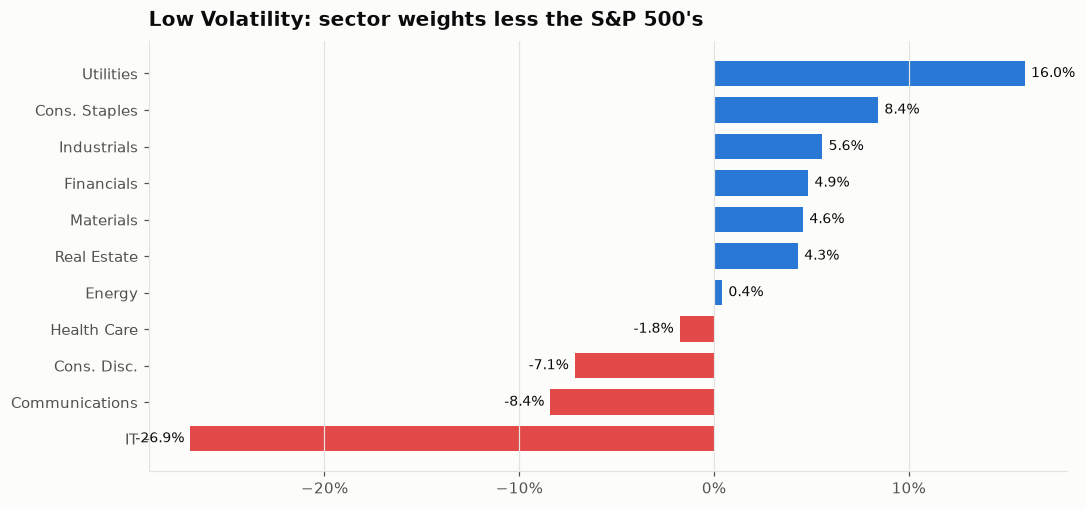

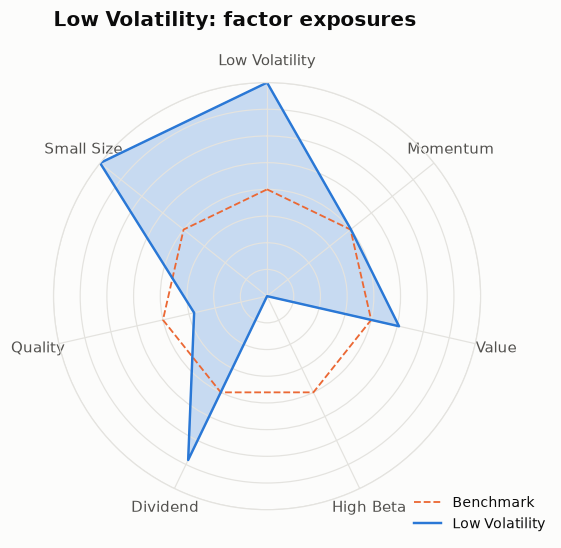


==================== High Beta ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-5.7%,-2.3%,8.1%,8.1%,6.5%,13.8%,9.6%,11.9%
Relative to SPY,-3.3%,-4.7%,-16.8%,-16.8%,-2.3%,-0.7%,-3.4%,-1.9%
Volatility,-,-,-,16.7%,26.9%,31.5%,26.2%,25.0%
Tracking error,-,-,-,11.5%,14.9%,18.9%,15.4%,14.2%


Book S&P 500
Portfolio         Companies                  110     503
                  Active share (stock)       88%      0%
                  Active share (sector)      26%      0%
                  Concentration (HH index)    91     199
                  Turnover (a year)         1.48       -
                  1-year beta to SPY        1.15    1.00
Weighted averages Stock volatility           37%     28%
                  12M - 1M price return      28%     38%
                  Book / price              0.45    0.20
                  Earnings / price          0.03    0.03
                  Sales / price             0.72    0.32
                  Stock beta                1.39    1.06
                  Yield (12M trailing)      1.5%    1.3%
                  Return on equity            4%     39%
                  Market value (USD bn)       71   1,046

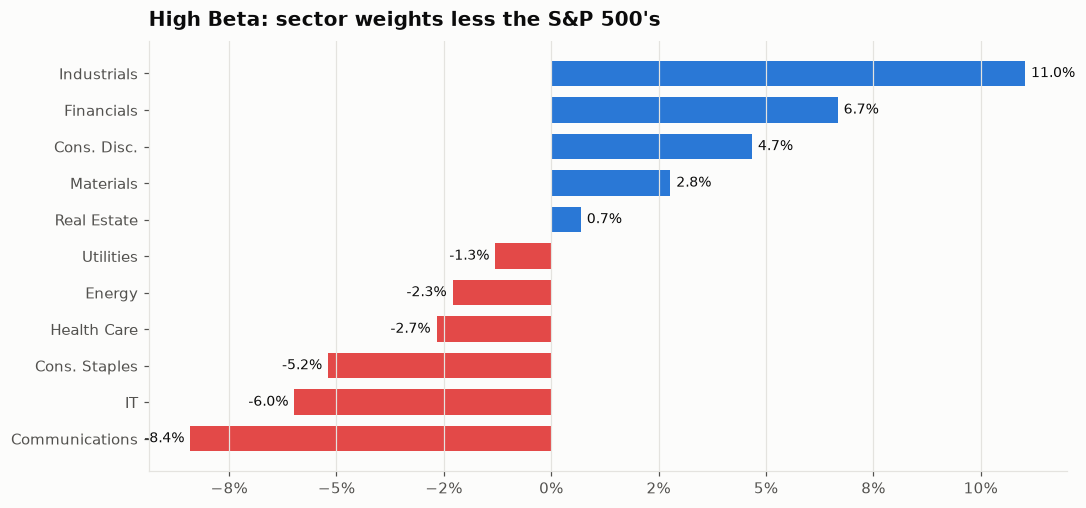

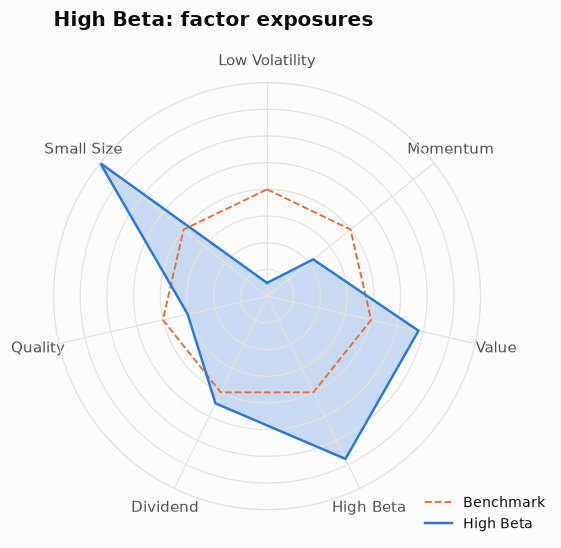


==================== High Dividend ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-7.2%,-3.1%,16.6%,16.6%,8.6%,11.9%,10.6%,13.2%
Relative to SPY,-4.8%,-5.6%,-8.3%,-8.3%,-0.2%,-2.6%,-2.4%,-0.6%
Volatility,-,-,-,15.0%,19.0%,23.5%,18.2%,16.2%
Tracking error,-,-,-,11.5%,12.3%,13.5%,10.6%,9.4%


Book S&P 500
Portfolio         Companies                   86     503
                  Active share (stock)       91%      0%
                  Active share (sector)      50%      0%
                  Concentration (HH index)   116     199
                  Turnover (a year)         0.92       -
                  1-year beta to SPY        0.51    1.00
Weighted averages Stock volatility           24%     28%
                  12M - 1M price return      17%     38%
                  Book / price              0.57    0.20
                  Earnings / price          0.03    0.03
                  Sales / price             0.82    0.32
                  Stock beta                0.48    1.06
                  Yield (12M trailing)      4.5%    1.3%
                  Return on equity            6%     39%
                  Market value (USD bn)       53   1,046

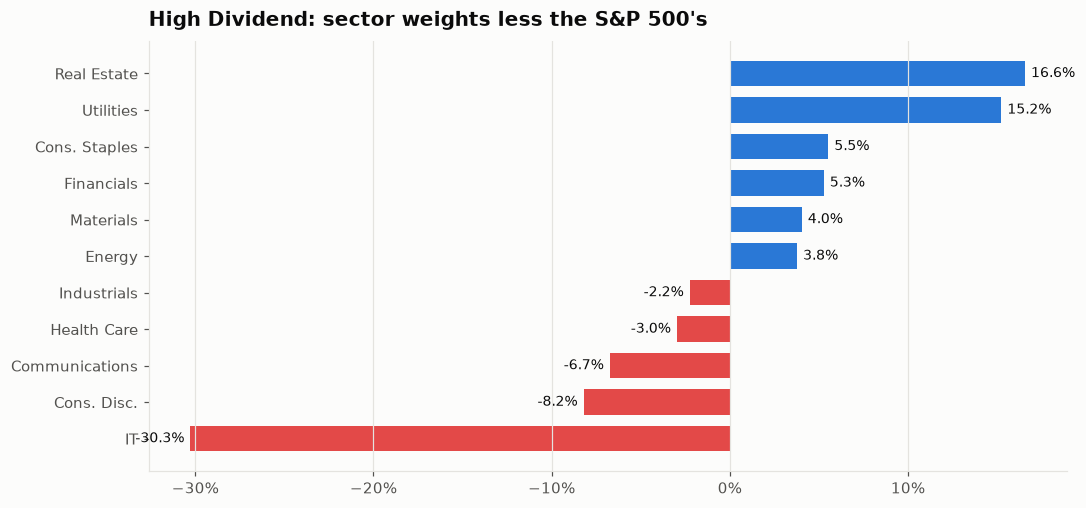

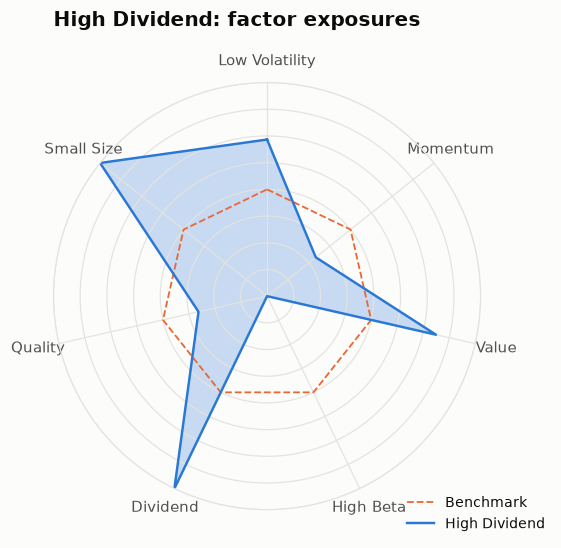


==================== Buyback ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-6.3%,-0.9%,16.3%,16.3%,7.8%,12.1%,10.7%,13.6%
Relative to SPY,-3.9%,-3.4%,-8.6%,-8.6%,-1.1%,-2.4%,-2.3%,-0.2%
Volatility,-,-,-,15.7%,19.0%,22.4%,18.9%,17.2%
Tracking error,-,-,-,9.2%,8.6%,9.6%,7.8%,6.6%


Book S&P 500
Portfolio         Companies                  109     503
                  Active share (stock)       87%      0%
                  Active share (sector)      32%      0%
                  Concentration (HH index)    92     199
                  Turnover (a year)         1.56       -
                  1-year beta to SPY        0.75    1.00
Weighted averages Stock volatility           27%     28%
                  12M - 1M price return      24%     38%
                  Book / price              0.37    0.20
                  Earnings / price          0.06    0.03
                  Sales / price             0.93    0.32
                  Stock beta                0.73    1.06
                  Yield (12M trailing)      1.5%    1.3%
                  Return on equity          -13%     39%
                  Market value (USD bn)      100   1,046

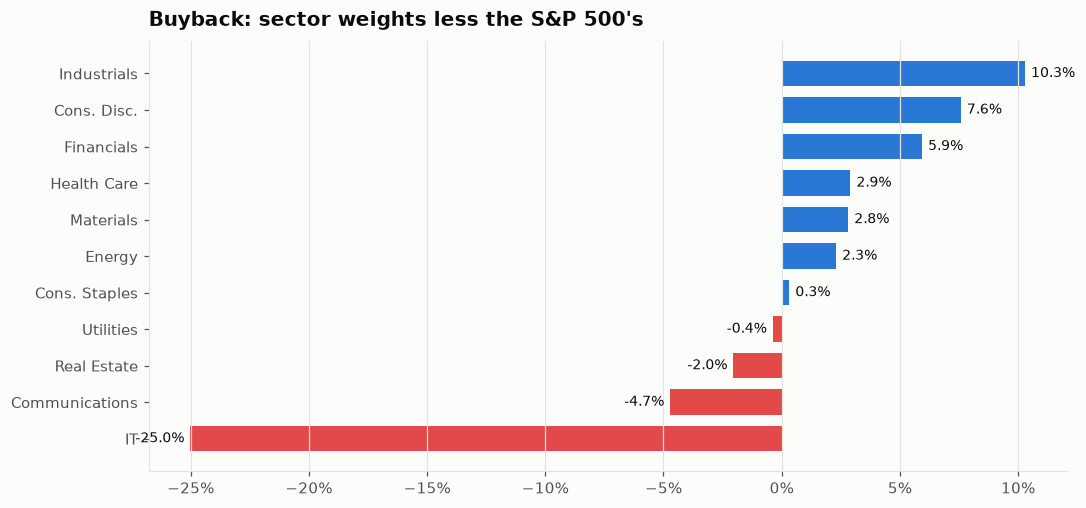

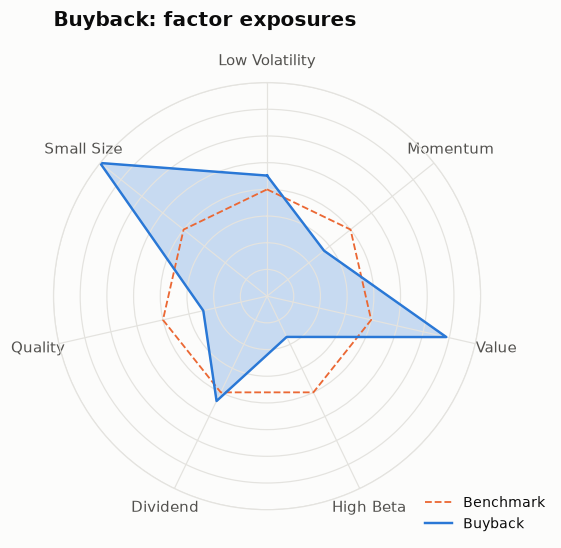


==================== GARP ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-6.8%,2.1%,17.3%,17.3%,5.8%,12.0%,9.5%,11.3%
Relative to SPY,-4.4%,-0.4%,-7.6%,-7.6%,-3.1%,-2.5%,-3.5%,-2.5%
Volatility,-,-,-,16.2%,20.2%,21.6%,18.4%,17.2%
Tracking error,-,-,-,9.7%,8.1%,7.5%,6.5%,6.0%


Book S&P 500
Portfolio         Companies                   75     503
                  Active share (stock)       86%      0%
                  Active share (sector)      36%      0%
                  Concentration (HH index)   151     199
                  Turnover (a year)         1.65       -
                  1-year beta to SPY        0.92    1.00
Weighted averages Stock volatility           33%     28%
                  12M - 1M price return      24%     38%
                  Book / price              0.36    0.20
                  Earnings / price          0.08    0.03
                  Sales / price             0.82    0.32
                  Stock beta                0.97    1.06
                  Yield (12M trailing)      1.5%    1.3%
                  Return on equity           33%     39%
                  Market value (USD bn)      179   1,046

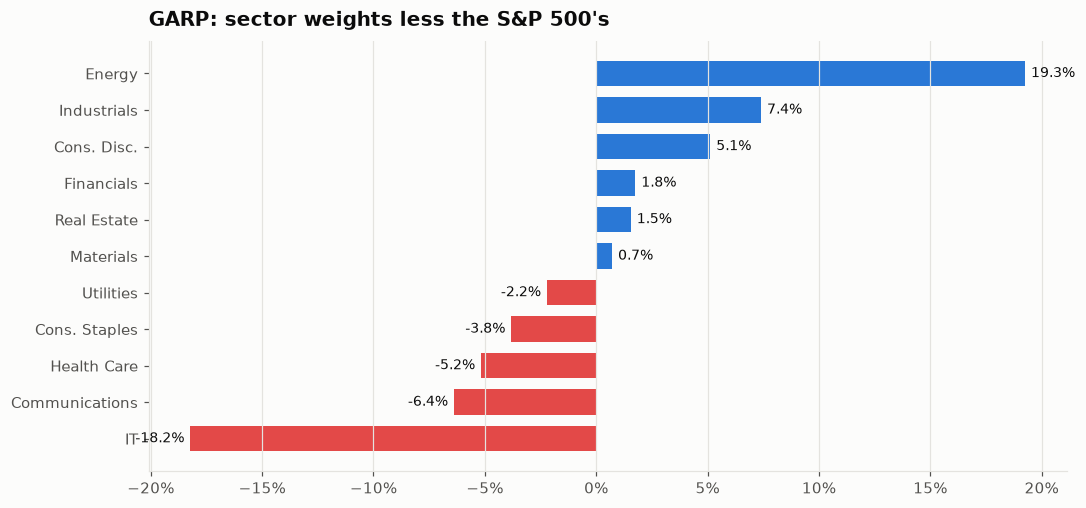

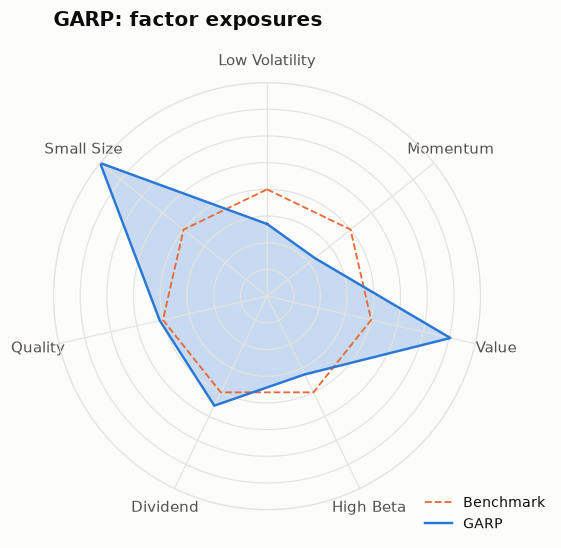


==================== Equal Weight ====================


,1M,3M,YTD,12M,3Y,5Y,10Y,15Y
Total return,-6.3%,-1.9%,13.0%,13.0%,4.8%,10.9%,10.4%,12.7%
Relative to SPY,-3.9%,-4.4%,-11.9%,-11.9%,-4.1%,-3.5%,-2.6%,-1.0%
Volatility,-,-,-,13.6%,18.6%,20.5%,17.0%,16.2%
Tracking error,-,-,-,7.2%,6.6%,6.7%,5.2%,4.5%


Book S&P 500
Portfolio         Companies                  503     503
                  Active share (stock)       54%      0%
                  Active share (sector)      25%      0%
                  Concentration (HH index)    20     199
                  Turnover (a year)            -       -
                  1-year beta to SPY        0.76    1.00
Weighted averages Stock volatility           27%     28%
                  12M - 1M price return      21%     38%
                  Book / price              0.34    0.20
                  Earnings / price          0.04    0.03
                  Sales / price             0.62    0.32
                  Stock beta                0.77    1.06
                  Yield (12M trailing)      1.9%    1.3%
                  Return on equity           15%     39%
                  Market value (USD bn)      105   1,046

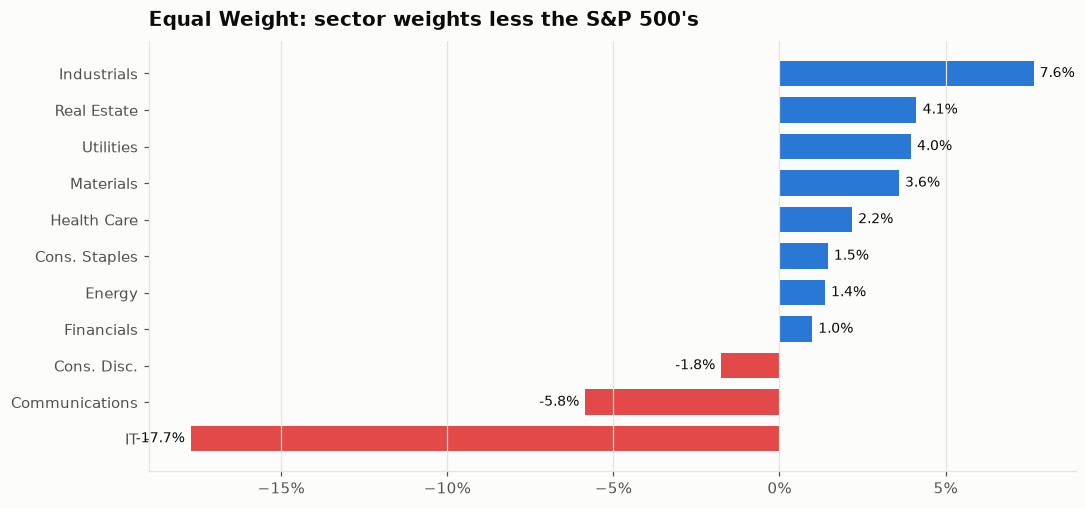

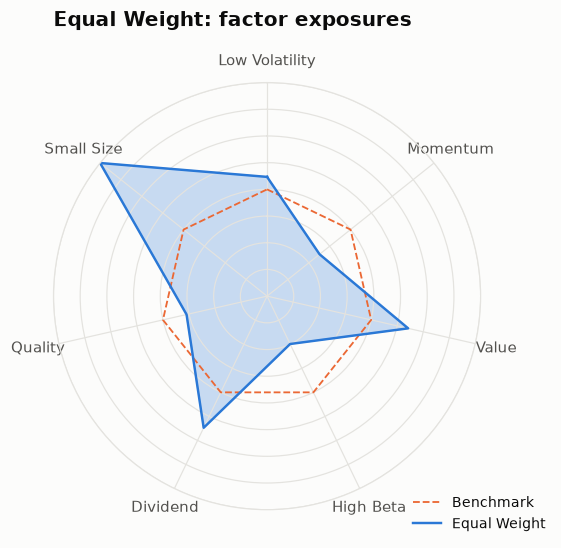

In [11]:
TRAITS = {
    "Stock volatility": ("volatility", "{:.0%}"),
    "12M - 1M price return": ("return_12_1", "{:.0%}"),
    "Book / price": ("book_to_price", "{:.2f}"),
    "Earnings / price": ("earnings_to_price", "{:.2f}"),
    "Sales / price": ("sales_to_price", "{:.2f}"),
    "Stock beta": ("beta", "{:.2f}"),
    "Yield (12M trailing)": ("dividend_yield", "{:.1%}"),
    "Return on equity": ("roe", "{:.0%}"),
}
turnover = {name: r.metrics["turnover"] for name, r in results.items()}
bench_year = bench.loc[:asof].tail(252)
for name in names:
    w = held[name]
    stats = pd.DataFrame(
        {
            "Total return": returns.loc[name],
            f"Relative to {BENCHMARK}": excess.loc[name],
            "Volatility": vols.loc[name].reindex(returns.columns),
            "Tracking error": tracking.loc[name].reindex(returns.columns),
        }
    ).T
    mine = daily[name].loc[:asof].tail(252)
    sector_active = db.active_share(db.sector_weights(w, sectors), db.sector_weights(index_weights, sectors))
    beta = mine.cov(bench_year.reindex(mine.index)) / bench_year.reindex(mine.index).var()
    portfolio = pd.DataFrame(
        {
            "Book": {
                "Companies": len(w),
                "Active share (stock)": f"{db.active_share(w, index_weights):.0%}",
                "Active share (sector)": f"{sector_active:.0%}",
                "Concentration (HH index)": f"{db.concentration(w):.0f}",
                "Turnover (a year)": f"{turnover[name]:.2f}" if name in turnover else "-",
                f"1-year beta to {BENCHMARK}": f"{beta:.2f}",
            },
            INDEX: {
                "Companies": len(index_weights),
                "Active share (stock)": "0%",
                "Active share (sector)": "0%",
                "Concentration (HH index)": f"{db.concentration(index_weights):.0f}",
                "Turnover (a year)": "-",
                f"1-year beta to {BENCHMARK}": "1.00",
            },
        }
    )
    averages = pd.DataFrame(
        {
            "Book": {label: fmt.format(db.weighted_average(w, traits[col])) for label, (col, fmt) in TRAITS.items()},
            INDEX: {
                label: fmt.format(db.weighted_average(index_weights, traits[col]))
                for label, (col, fmt) in TRAITS.items()
            },
        }
    )
    averages.loc[f"Market value ({data.currency} bn)"] = [
        f"{db.weighted_average(w, traits['market_cap']) / 1e9:,.0f}",
        f"{db.weighted_average(index_weights, traits['market_cap']) / 1e9:,.0f}",
    ]
    tilts = db.sector_weights(w, sectors).sub(db.sector_weights(index_weights, sectors), fill_value=0.0)
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    display(stats.style.format("{:.1%}", na_rep="-").map(red_negatives))
    display(pd.concat({"Portfolio": portfolio, "Weighted averages": averages}))
    charts.ranked_bars(tilts, f"{name}: sector weights less the {INDEX}'s", percent=True)
    plt.show()
    charts.radar({name: exposure.loc[name]}, f"{name}: factor exposures")
    plt.show()

## Findings

*These findings describe the default books on 31 December 2024; with other runs in `RUNS` they no longer apply.*

* **2024 belonged to quality and momentum.** Of the nine portfolios only Quality (+32.1 %) and Momentum (+30.8 %) beat
  SPY (+24.9 %); every portfolio tilted away from the largest companies trailed it - Equal Weight by 11.9 points,
  High Beta by 16.8.
* **Over 15 years, only Quality beat SPY**: +1.8 % a year, with a tracking error of 4.6 % (only Equal Weight's, 4.5 %,
  was lower). Value trailed most (-3.1 % a year); Low Volatility had the lowest volatility (11.8 % against SPY's
  14.6 %) at a cost of 1.9 % a year; Momentum was ahead over ten years (+0.3 %) but not over fifteen (-0.4 %).
* **Most portfolios are one bet in disguise.** Value, High Beta, High Dividend, Buyback, GARP and Equal Weight have
  correlated excess returns (0.3-0.8) and all tilt towards **smaller companies** (small-size exposures of +1.6 to
  +1.8, Value's +0.55); in a decade led by mega-caps, that common size bet cost them. Quality is their mirror image
  (correlations of -0.25 to -0.66) and shares 52 % of its weight with the S&P 500.
* **Each portfolio has the intended exposure** - Value to value (+1.27), Low Volatility to low volatility (+1.16),
  Momentum to momentum (+1.06), High Dividend to dividend yield (+2.01) - a check that the construction does what it
  is meant to.

These are our portfolios on our data, not S&P's indices (see below). The S&P 500's own statistics here - a
concentration of 199 and a stock beta of 1.06 - are close to the dashboard's (230 and 1.08), which suggests our
calculations match S&P's.

## Differences from S&P's dashboard

* **Backtested portfolios, not indices.** Every default "index" is our backtest of rules in the spirit of S&P's, net of our
  trading costs; S&P's official index levels and holdings are not licensed to us (see notebook 3.5). Weights follow two
  simple schemes (cap-weighted or equal) where S&P weights by scores, volatility or dividends.
* **Period.** "15Y" is 2010-2024 and the date is 31 December 2024; the dashboard's later months fall in our hold-out.
* **Sectors** are today's GICS sectors for every date; S&P also shows industry groups.
* **Factor exposures** are weighted z-scores relative to the S&P 500 (in standard deviations), not S&P's percentile
  scale.
* **Omitted:** S&P 500 Growth, Pure Growth, Pure Value, Revenue-Weighted, Economic Moat, Quality FCF Aristocrats,
  Dividend Aristocrats and Low Volatility High Dividend - they need style scores, Morningstar's moat ratings or long
  dividend histories we do not have (the last could be added).

## Glossary

* **Excess (relative) return** - a portfolio's return minus SPY's over the same period.
* **Tracking error** - the annualised standard deviation of the excess return.
* **Information ratio** - annualised excess return divided by tracking error.
* **Active share** - the fraction of a portfolio's weight that differs from the S&P 500's.
* **Concentration (Herfindahl-Hirschman index)** - the sum of squared weights in percent: 10,000 for a single stock,
  100 for a hundred equal weights; $10{,}000/\text{HHI}$ is the *effective number* of holdings.
* **Overlap** - the weight two portfolios hold in common.